#### Inputs:
* Training spectrograms (6,393 × 128 × 128)
* Genre labels (8 classes)

#### Purpose:
* Look at the training data to get a feel for how genres differ visually in their spectrograms before building any models.

#### Outputs:
* EDA visualizations saved to `../reports/`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the data
data = np.load('../data/local/mel_compact.npz')
X_train = data['X_train']  # shape: (6393, 128, 128)
y_train = data['y_train']  # shape: (6393,)

# Genre label lookup
genre_map = {
    0: 'Electronic',
    1: 'Experimental',
    2: 'Folk',
    3: 'Hip-Hop',
    4: 'Instrumental',
    5: 'International',
    6: 'Pop',
    7: 'Rock'
}
genre_names = [genre_map[i] for i in range(8)]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Unique genres:", np.unique(y_train))

X_train shape: (6393, 128, 128)
y_train shape: (6393,)
Unique genres: [0 1 2 3 4 5 6 7]


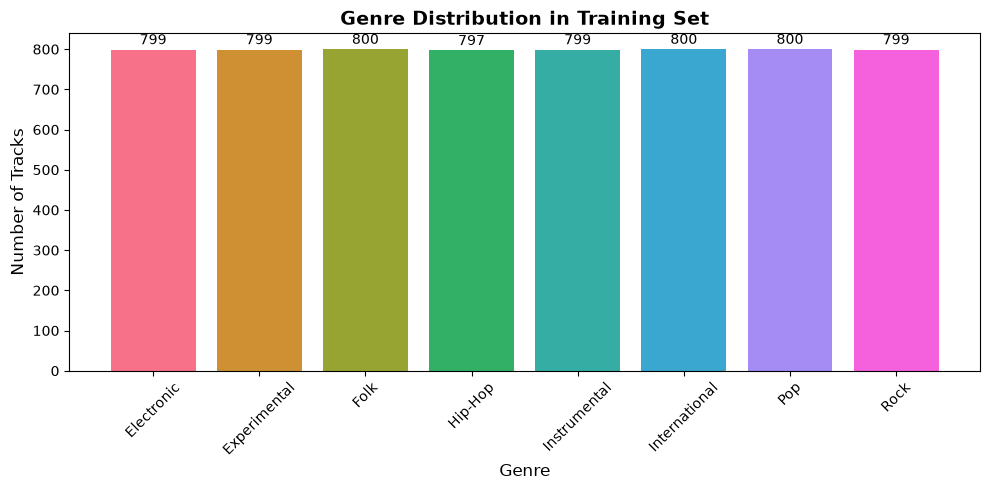

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))

unique, counts = np.unique(y_train, return_counts=True)
colors = sns.color_palette("husl", 8)

bars = ax.bar([genre_map[i] for i in unique], counts, color=colors)
ax.set_title('Genre Distribution in Training Set', fontsize=14, fontweight='bold')
ax.set_xlabel('Genre', fontsize=12)
ax.set_ylabel('Number of Tracks', fontsize=12)
ax.tick_params(axis='x', rotation=45)

# Add count labels on bars
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(count), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../reports/eda_genre_distribution.png', dpi=150)
plt.show()

## Interpretation: Genre Distribution in Training Set

The training set is nearly perfectly balanced — each genre has between 797 and 800 tracks, 6,393 total. This is good news for modeling since we don't need to worry about class imbalance skewing our results, and accuracy is a fair metric to use.

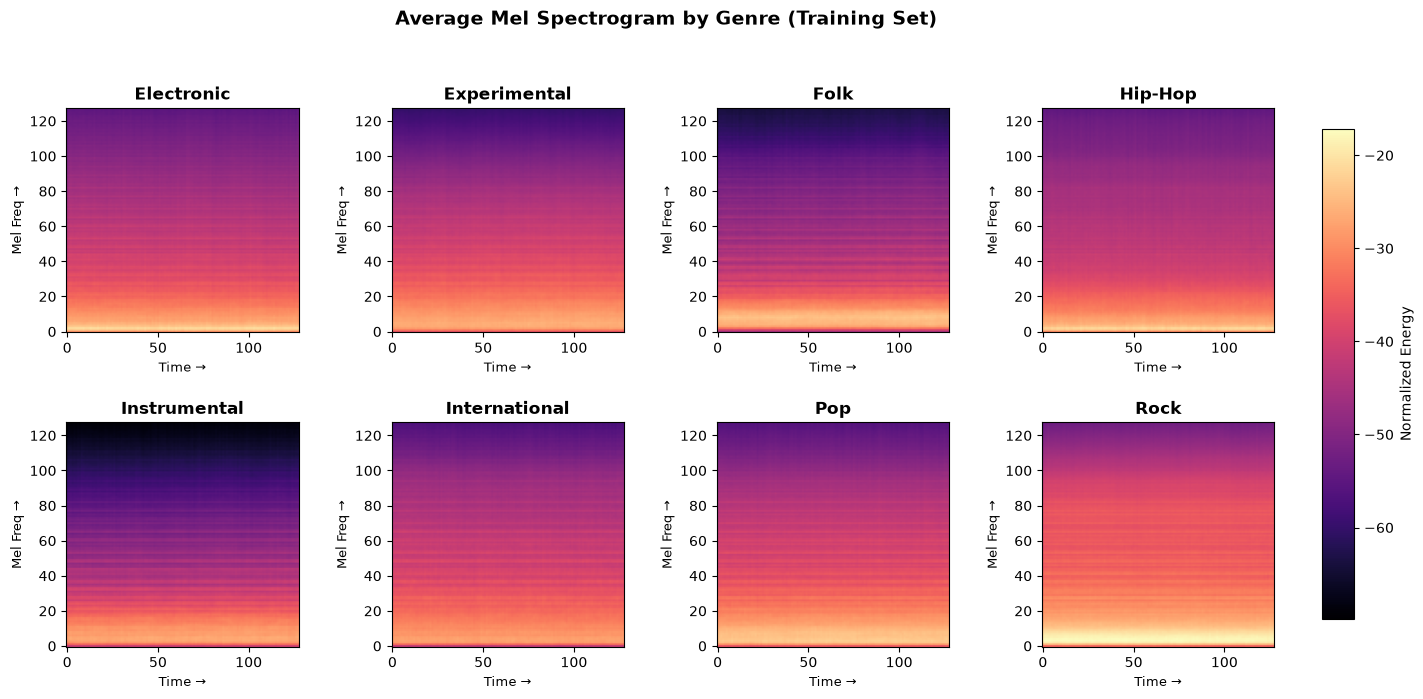

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

# compute average spectrogram per genre
avg_specs = []
for genre_id in range(8):
    genre_specs = X_train[y_train == genre_id]
    avg_specs.append(np.mean(genre_specs, axis=0))

# get global min/max for consistent color scale
vmin = min(s.min() for s in avg_specs)
vmax = max(s.max() for s in avg_specs)

# plot each genre's average
for genre_id in range(8):
    im = axes[genre_id].imshow(avg_specs[genre_id], aspect='auto', origin='lower',
                                cmap='magma', vmin=vmin, vmax=vmax)
    axes[genre_id].set_title(genre_map[genre_id], fontsize=12, fontweight='bold')
    axes[genre_id].set_xlabel('Time →', fontsize=9)
    axes[genre_id].set_ylabel('Mel Freq →', fontsize=9)  # shortened to avoid cutoff

fig.suptitle('Average Mel Spectrogram by Genre (Training Set)',
             fontsize=14, fontweight='bold', y=1.02)
fig.subplots_adjust(right=0.88, hspace=0.4, wspace=0.4)  # hspace for row spacing, wspace for label room
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label='Normalized Energy')
plt.savefig('../reports/eda_avg_spectrogram_per_genre.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation: Average Mel Spectrogram by Genre (Training Set)

Each genre has a noticeably different average spectrogram pattern. Folk and Instrumental both show brighter energy concentrated in the lower frequency bands, while Electronic and Hip-Hop spread more evenly across frequencies. Instrumental is also notably darker overall which lines up with its lower mean energy. Rock and Pop both show relatively bright mid-to-high frequency content.

The fact that these differences are visible even in the averages suggests a CNN should be able to pick up on genre-specific patterns directly from the spectrograms.

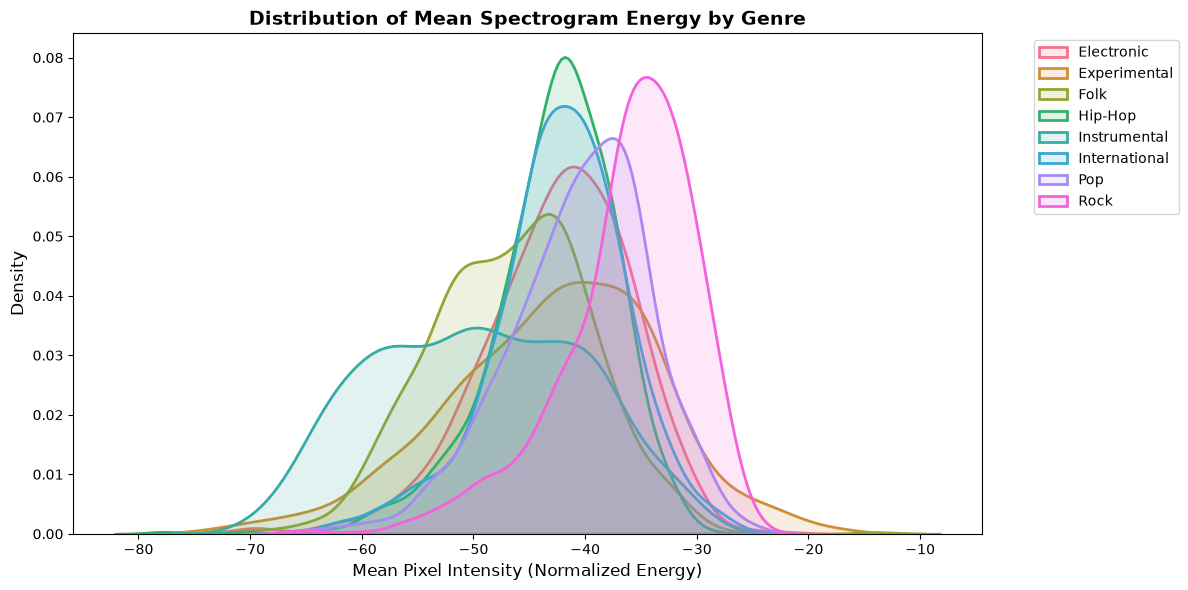

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette("husl", 8)

for genre_id in range(8):
    genre_specs = X_train[y_train == genre_id]
    mean_per_track = genre_specs.mean(axis=(1, 2))
    sns.kdeplot(mean_per_track, ax=ax, 
                label=genre_map[genre_id], 
                color=colors[genre_id], 
                linewidth=2, fill=True, alpha=0.15)

ax.set_title('Distribution of Mean Spectrogram Energy by Genre', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Pixel Intensity (Normalized Energy)', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/eda_intensity_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation: Distribution of Mean Spectrogram Energy by Genre

You can see pretty clear separation between genres here. Rock and Electronic 
are shifted right toward higher energy, while Folk and Instrumental sit much 
further left - Instrumental especially has a wide flat curve which tracks with 
the high variance we've seen from it throughout. Hip-Hop stands out with a 
sharp, narrow peak around -40 dB, meaning its tracks are unusually consistent 
in energy. Experimental and Pop/International all bunch up near the center and 
overlap a lot, which suggests mean energy alone won't be enough to tell those 
apart.

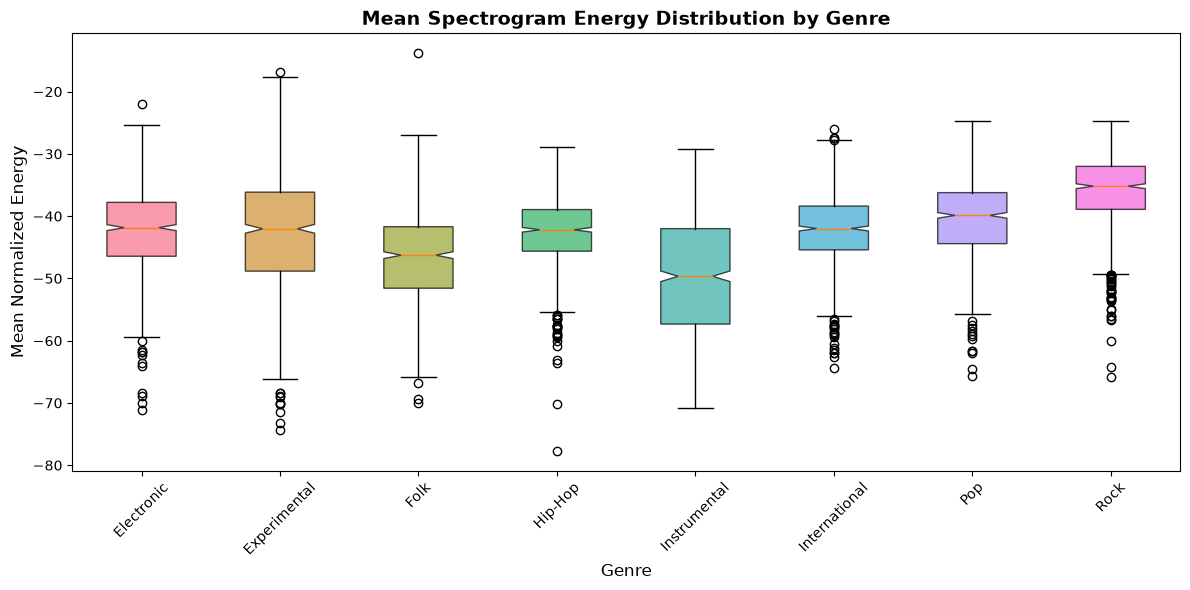

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

box_data = []
for genre_id in range(8):
    genre_specs = X_train[y_train == genre_id]
    mean_energies = genre_specs.mean(axis=(1, 2))
    box_data.append(mean_energies)

bp = ax.boxplot(box_data, tick_labels=genre_names, patch_artist=True, notch=True)

colors = sns.color_palette("husl", 8)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title('Mean Spectrogram Energy Distribution by Genre', fontsize=14, fontweight='bold')
ax.set_xlabel('Genre', fontsize=12)
ax.set_ylabel('Mean Normalized Energy', fontsize=12)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../reports/eda_energy_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation: Mean Spectrogram Energy Distribution by Genre

The boxplot makes the separation between genres much more concrete. Rock sits 
noticeably higher than everything else, with a tight IQR that confirms it's 
not just a few loud outliers pulling the median up. Pop and International are 
close behind, while Hip-Hop has one of the tightest boxes overall - consistent 
with what we saw in the KDE. On the quieter end, Folk and Instrumental both 
have lower medians, and Instrumental's box is the widest of the group, meaning 
track-to-track energy varies a lot within that genre. Experimental has the most 
outliers by far, which makes sense given how sonically diverse that category is.

The clear vertical separation between Rock/Electronic and Folk/Instrumental 
suggests mean energy will be one of the stronger features for the model to 
lean on.

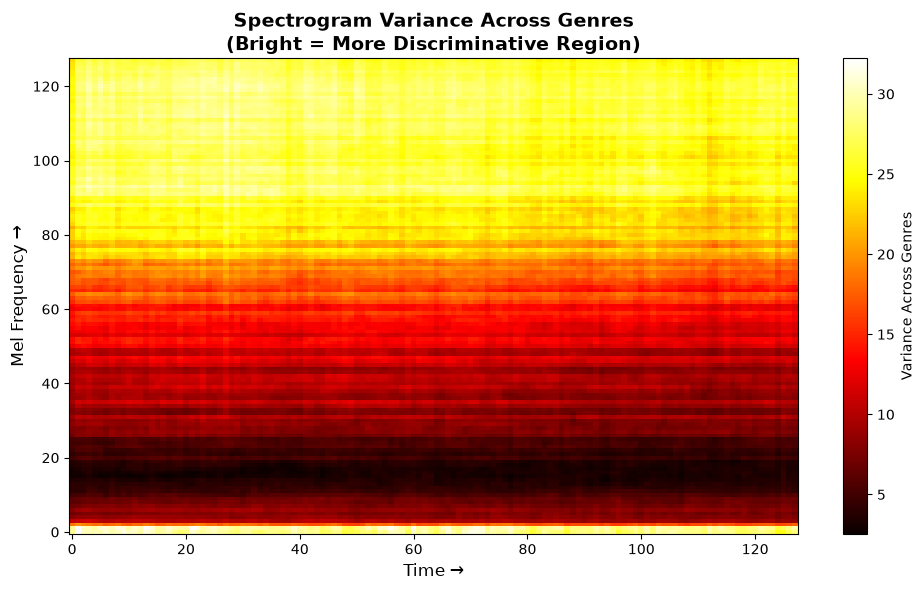

In [6]:
# Compute average spectrogram per genre
genre_avgs = []
for genre_id in range(8):
    genre_specs = X_train[y_train == genre_id]
    genre_avgs.append(genre_specs.mean(axis=0))  # shape: (128, 128) — DON'T flatten

genre_avgs = np.array(genre_avgs)  # shape: (8, 128, 128)

# Compute variance ACROSS genres at each pixel position
# High variance = this frequency/time region differs a lot between genres = useful for classification
variance_map = genre_avgs.var(axis=0)  # shape: (128, 128)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(variance_map, aspect='auto', origin='lower', cmap='hot')
plt.colorbar(im, ax=ax, label='Variance Across Genres')

ax.set_title('Spectrogram Variance Across Genres\n(Bright = More Discriminative Region)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Time →', fontsize=12)
ax.set_ylabel('Mel Frequency →', fontsize=12)

plt.tight_layout()
plt.savefig('../reports/eda_genre_variance_map.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation: Spectrogram Variance Across Genres

The bright region sitting in the mid-to-high frequency bands (roughly Mel bins 
70-128) is the most interesting part of this plot - that's where genres actually 
differ from each other. The bottom of the map stays consistently dark, which 
tells you that bass-range content looks pretty similar regardless of genre and 
won't help the model much.

What's also notable is how uniform the variance looks left-to-right across time. 
There's no particular moment in a track where genres become more or less 
distinguishable - the discriminative signal is spread evenly across the full 
duration. That's a reasonable justification for using a 2D CNN here rather than 
something purely temporal, since the spatial frequency structure carries more 
information than the time axis alone.

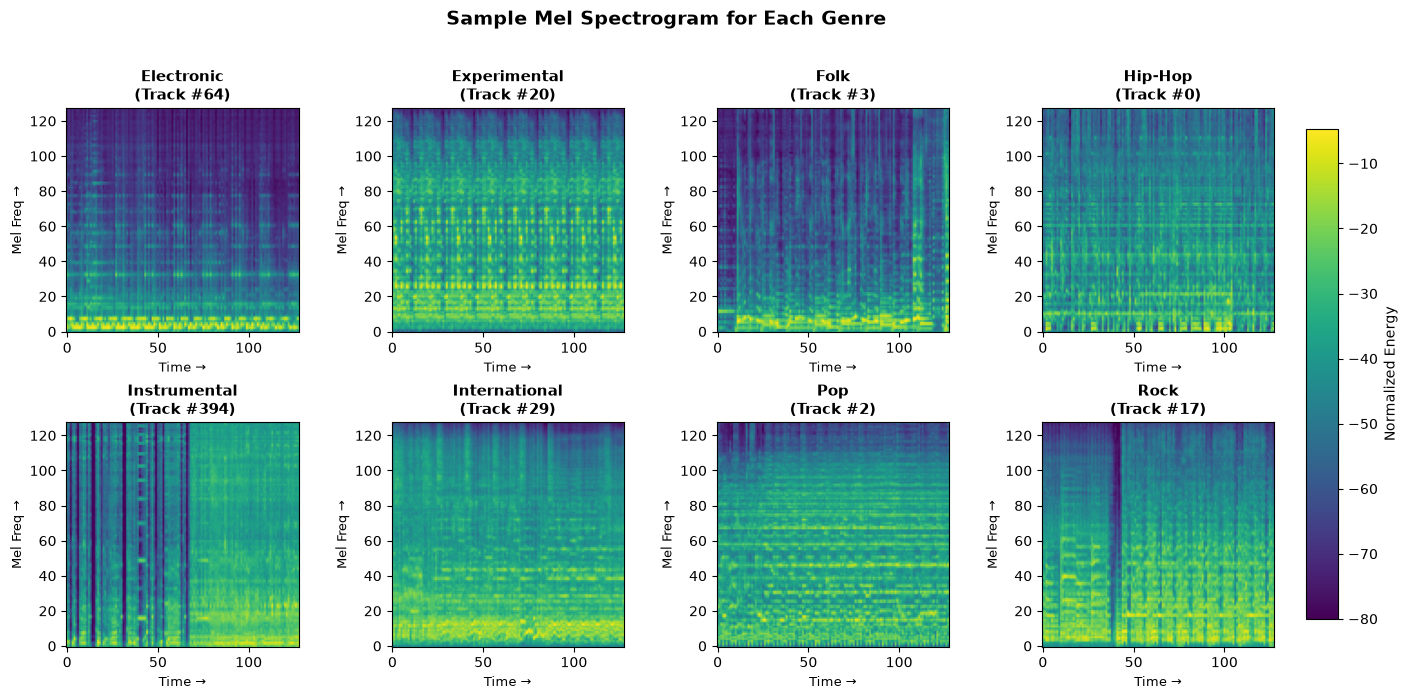

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for genre_id in range(8):
    # Get first track of this genre
    idx = np.where(y_train == genre_id)[0][0]
    spec = X_train[idx]

    im = axes[genre_id].imshow(spec, aspect='auto', origin='lower', cmap='viridis')
    axes[genre_id].set_title(f'{genre_map[genre_id]}\n(Track #{idx})',
                            fontsize=11, fontweight='bold')
    axes[genre_id].set_xlabel('Time →', fontsize=9)
    axes[genre_id].set_ylabel('Mel Freq →', fontsize=9)

fig.suptitle('Sample Mel Spectrogram for Each Genre',
            fontsize=14, fontweight='bold', y=1.02)

fig.subplots_adjust(right=0.88, hspace=0.4, wspace=0.4)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
fig.colorbar(im, cax=cbar_ax, label='Normalized Energy')

plt.savefig('../reports/eda_sample_spectrograms.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation: Sample Mel Spectrogram for Each Genre

Looking at individual tracks is a good reality check - the intra-genre 
variation is high enough that no single example is fully "representative," 
but some structural patterns do come through. The Instrumental track is the 
most visually distinct, with strong vertical stripes that likely correspond 
to song transitions or silence gaps. Folk sits quiet and low-frequency heavy 
throughout, while Hip-Hop looks unusually uniform across the whole 
spectrogram - consistent with the tight energy distribution we've seen from 
it in every plot so far. Rock has a few sharp bright bursts in the upper 
frequencies, and Experimental lives up to its name with the most scattered, 
hard-to-describe pattern of the eight.

These individual examples also reinforce why classification isn't trivial - 
Electronic, International, and Pop all look fairly similar at this scale, 
which lines up with the overlap we saw in the KDE and boxplots earlier.